In [1]:
import os, sys, glob, subprocess, warnings
warnings.filterwarnings("ignore")
try:
    import kagglehub
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler



In [2]:
SEED = 42
np.random.seed(SEED)
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

In [3]:
DATA_DIR = None

if DATA_DIR is None:
    DATA_DIR = kagglehub.dataset_download("rocki37/open-university-learning-analytics-dataset")
print("Data folder:", DATA_DIR)

def find_csv(name):
    hits = glob.glob(os.path.join(DATA_DIR, "**", f"{name}.csv"), recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name}.csv not found under {DATA_DIR}")
    return hits[0]

100%|██████████| 84.3M/84.3M [00:00<00:00, 172MB/s]

Extracting files...


Data folder: /root/.cache/kagglehub/datasets/rocki37/open-university-learning-analytics-dataset/versions/1


In [4]:
KEY = ["code_module", "code_presentation", "id_student"]
NA = ["?", ""]
CUTS = [14, 28, 42, 56, 84, 112, 140]
PRIMARY = 56
MAXCUT = max(CUTS)

student_info = pd.read_csv(find_csv("studentInfo"), na_values=NA)
reg = pd.read_csv(find_csv("studentRegistration"), na_values=NA)[KEY + ["date_registration", "date_unregistration"]]
assessments = pd.read_csv(find_csv("assessments"), na_values=NA)
student_assess = pd.read_csv(find_csv("studentAssessment"), na_values=NA)
for c in ["date_registration", "date_unregistration"]:
    reg[c] = pd.to_numeric(reg[c], errors="coerce")
assessments["date"] = pd.to_numeric(assessments["date"], errors="coerce")
student_assess["score"] = pd.to_numeric(student_assess["score"], errors="coerce")
student_assess["date_submitted"] = pd.to_numeric(student_assess["date_submitted"], errors="coerce")

vle = pd.read_csv(find_csv("studentVle"), na_values=NA,
                  usecols=KEY + ["date", "sum_click"],
                  dtype={"id_student": "int32", "date": "int16", "sum_click": "int32",
                         "code_module": "category", "code_presentation": "category"})
n_vle_rows = len(vle)
vle = vle[vle["date"] <= MAXCUT]
daily = (vle.groupby(KEY + ["date"], observed=True, as_index=False)["sum_click"].sum())
daily["code_module"] = daily["code_module"].astype(str)
daily["code_presentation"] = daily["code_presentation"].astype(str)
del vle

print("studentInfo rows:", len(student_info))
print("studentVle rows (raw):", n_vle_rows)

studentInfo rows: 32593
studentVle rows (raw): 10655280


In [5]:
student_info["at_risk"] = student_info["final_result"].isin(["Fail", "Withdrawn"]).astype(int)
desc = (student_info.groupby(["code_module", "code_presentation"])
        .agg(enrollments=("id_student", "size"), at_risk_rate=("at_risk", "mean"))
        .reset_index())
desc["at_risk_rate"] = desc["at_risk_rate"].round(3)
print("Unique students:", student_info["id_student"].nunique(), "| enrollments:", len(student_info))
print("Overall at-risk rate (Fail+Withdrawn):", round(student_info["at_risk"].mean(), 3))
print(student_info["final_result"].value_counts().to_string())
desc.to_csv(f"{OUT}/table_dataset_description.csv", index=False)
desc

Unique students: 28785 | enrollments: 32593
Overall at-risk rate (Fail+Withdrawn): 0.528
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024


,code_module,code_presentation,enrollments,at_risk_rate
0,AAA,2013J,383,0.274
1,AAA,2014J,365,0.307
2,BBB,2013B,1767,0.546
3,BBB,2013J,2237,0.521
4,BBB,2014B,1613,0.549
5,BBB,2014J,2292,0.497
6,CCC,2014B,1936,0.658
7,CCC,2014J,2498,0.594
8,DDD,2013B,1303,0.609
9,DDD,2013J,1938,0.572


In [6]:
base_all = student_info.merge(reg, on=KEY, how="left")
non_exam = assessments[assessments["assessment_type"] != "Exam"].copy()

def build_features(T):
    base = base_all.copy()
    still = base["date_unregistration"].isna() | (base["date_unregistration"] > T)
    joined = base["date_registration"].isna() | (base["date_registration"] <= T)
    base = base[still & joined].copy()

    d = daily[daily["date"] <= T]
    eng = d.groupby(KEY, as_index=False).agg(total_clicks=("sum_click", "sum"),
                                              active_days=("date", "nunique"))
    rec = (d[d["date"] > T - 14].groupby(KEY, as_index=False)["sum_click"].sum()
           .rename(columns={"sum_click": "clicks_last14"}))
    base = base.merge(eng, on=KEY, how="left").merge(rec, on=KEY, how="left")
    for c in ["total_clicks", "active_days", "clicks_last14"]:
        base[c] = base[c].fillna(0)
    base["clicks_per_active_day"] = np.where(base["active_days"] > 0,
                                             base["total_clicks"] / base["active_days"].clip(lower=1), 0)
    base["log_total_clicks"] = np.log1p(base["total_clicks"])
    base["log_clicks_last14"] = np.log1p(base["clicks_last14"])
    base["log_clicks_per_day"] = np.log1p(base["clicks_per_active_day"])

    due = (non_exam[non_exam["date"] <= T].groupby(["code_module", "code_presentation"])
           .size().rename("n_due").reset_index())
    sa = student_assess.merge(non_exam[["id_assessment", "code_module", "code_presentation"]],
                              on="id_assessment", how="inner")
    sa = sa[sa["date_submitted"] <= T]
    sa = sa.merge(non_exam[["id_assessment", "date"]], on="id_assessment", how="left")
    sa = sa[sa["date"] <= T]
    ag = sa.groupby(KEY, as_index=False).agg(n_submitted=("id_assessment", "nunique"),
                                              mean_score=("score", "mean"))
    base = base.merge(due, on=["code_module", "code_presentation"], how="left")
    base = base.merge(ag, on=KEY, how="left")
    base["n_due"] = base["n_due"].fillna(0)
    base["n_submitted"] = base["n_submitted"].fillna(0)
    base["submit_rate"] = np.where(base["n_due"] > 0,
                                   (base["n_submitted"] / base["n_due"].clip(lower=1)).clip(upper=1), np.nan)
    base["split"] = np.where(base["code_presentation"].str.startswith("2013"), "train", "test")
    return base

CAT = ["code_module"]
ENG = ["log_total_clicks", "active_days", "log_clicks_last14", "log_clicks_per_day"]
LEARN = ["n_submitted", "mean_score", "submit_rate"]
FEATURE_SETS = {"Engagement only": ENG,
                "Assessment only": LEARN,
                "Engagement + Assessment": ENG + LEARN}

def make_pipe(kind, num):
    cat_enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    if kind == "lr":
        num_pipe = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                             ("sc", StandardScaler())])
        clf = LogisticRegression(max_iter=2000)
    else:
        num_pipe = "passthrough"
        clf = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200,
                                             random_state=SEED)
    pre = ColumnTransformer([("num", num_pipe, num), ("cat", cat_enc, CAT)])
    return Pipeline([("pre", pre), ("clf", clf)])

def precision_at_k(y, s, frac=0.10):
    k = max(1, int(len(y) * frac))
    idx = np.argsort(-s)[:k]
    return float(np.mean(y[idx]))

In [7]:
rows, primary_scores = [], {}
primary_df = None
for T in CUTS:
    df = build_features(T)
    tr, te = df[df["split"] == "train"], df[df["split"] == "test"]
    if len(tr) == 0 or len(te) == 0:
        raise RuntimeError("Train/test split is empty: check code_presentation values.")
    ytr, yte = tr["at_risk"].values, te["at_risk"].values
    for fs_name, cols in FEATURE_SETS.items():
        for kind in ["gb", "lr"]:
            pipe = make_pipe(kind, cols)
            pipe.fit(tr[cols + CAT], ytr)
            s = pipe.predict_proba(te[cols + CAT])[:, 1]
            rows.append(dict(cutoff_day=T, features=fs_name, model=kind,
                             n_train=len(tr), n_test=len(te),
                             auc=roc_auc_score(yte, s), ap=average_precision_score(yte, s),
                             precision_at_10pct=precision_at_k(yte, s, 0.10)))
            if T == PRIMARY and kind == "gb":
                primary_scores[fs_name] = s
    if T == PRIMARY:
        primary_df = df
    print(f"cutoff day {T}: train={len(tr)}, test={len(te)}, at-risk rate test={yte.mean():.3f}")

results = pd.DataFrame(rows)
results.round(4).to_csv(f"{OUT}/table_results_all.csv", index=False)
main_tab = (results[(results.cutoff_day == PRIMARY)]
            .pivot(index="features", columns="model", values=["auc", "precision_at_10pct"]).round(3))
main_tab.to_csv(f"{OUT}/table_main_cutoff.csv")
main_tab

cutoff day 14: train=12076, test=15985, at-risk rate test=0.449
cutoff day 28: train=11802, test=15720, at-risk rate test=0.439
cutoff day 42: train=11614, test=15398, at-risk rate test=0.428
cutoff day 56: train=11426, test=15087, at-risk rate test=0.416
cutoff day 84: train=11131, test=14589, at-risk rate test=0.396
cutoff day 112: train=10775, test=14155, at-risk rate test=0.377
cutoff day 140: train=10512, test=13777, at-risk rate test=0.360


auc        precision_at_10pct       
model                       gb     lr                 gb     lr
features                                                       
Assessment only          0.767  0.760              0.899  0.932
Engagement + Assessment  0.793  0.798              0.910  0.944
Engagement only          0.750  0.749              0.894  0.885

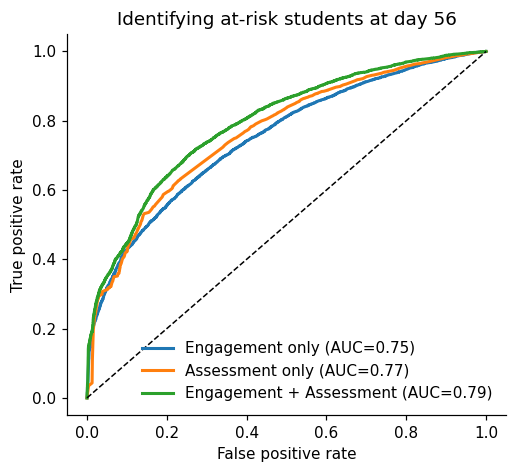

In [8]:
te_main = primary_df[primary_df["split"] == "test"]
y_main = te_main["at_risk"].values
fig, ax = plt.subplots(figsize=(4.8, 4.4))
for fs_name, s in primary_scores.items():
    fpr, tpr, _ = roc_curve(y_main, s)
    ax.plot(fpr, tpr, label=f"{fs_name} (AUC={roc_auc_score(y_main, s):.2f})", lw=2)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title(f"Identifying at-risk students at day {PRIMARY}")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(f"{OUT}/fig1_roc.png"); plt.show()

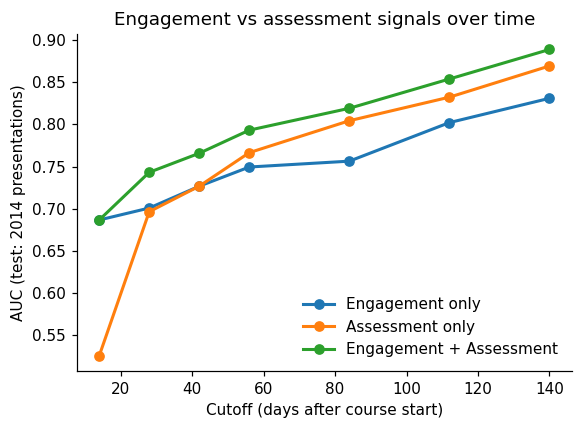

In [9]:
gb = results[results["model"] == "gb"]
fig, ax = plt.subplots(figsize=(5.4, 4.0))
for fs_name in FEATURE_SETS:
    g = gb[gb["features"] == fs_name].sort_values("cutoff_day")
    ax.plot(g["cutoff_day"], g["auc"], marker="o", lw=2, label=fs_name)
ax.set_xlabel("Cutoff (days after course start)"); ax.set_ylabel("AUC (test: 2014 presentations)")
ax.set_title("Engagement vs assessment signals over time")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{OUT}/fig2_auc_over_time.png"); plt.show()

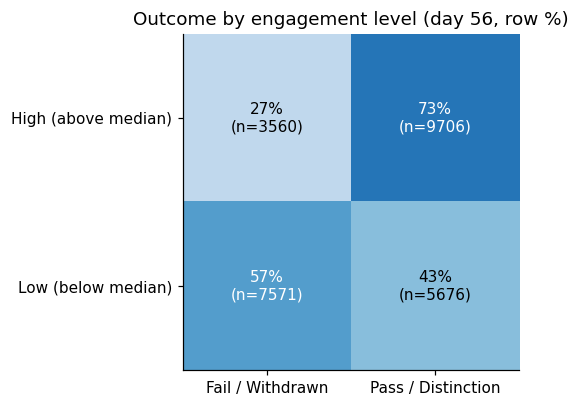

Share of at-risk students who are HIGH engagement: 0.32


In [10]:
d3 = primary_df.copy()
d3["eng_rank"] = d3.groupby(["code_module", "code_presentation"])["total_clicks"].rank(pct=True)
d3["Engagement"] = np.where(d3["eng_rank"] > 0.5, "High (above median)", "Low (below median)")
d3["Outcome"] = np.where(d3["at_risk"] == 1, "Fail / Withdrawn", "Pass / Distinction")
ct = pd.crosstab(d3["Engagement"], d3["Outcome"])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
ct.to_csv(f"{OUT}/table_engagement_vs_outcome_counts.csv")
fig, ax = plt.subplots(figsize=(5.2, 3.8))
im = ax.imshow(ct_pct.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns)
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f"{ct_pct.values[i, j]:.0f}%\n(n={ct.values[i, j]})", ha="center", va="center",
                color="white" if ct_pct.values[i, j] > 55 else "black")
ax.set_title(f"Outcome by engagement level (day {PRIMARY}, row %)")
fig.tight_layout(); fig.savefig(f"{OUT}/fig3_engagement_vs_outcome.png"); plt.show()
high_eng_share_of_atrisk = ct.loc["High (above median)", "Fail / Withdrawn"] / ct["Fail / Withdrawn"].sum()
print("Share of at-risk students who are HIGH engagement:", round(float(high_eng_share_of_atrisk), 3))

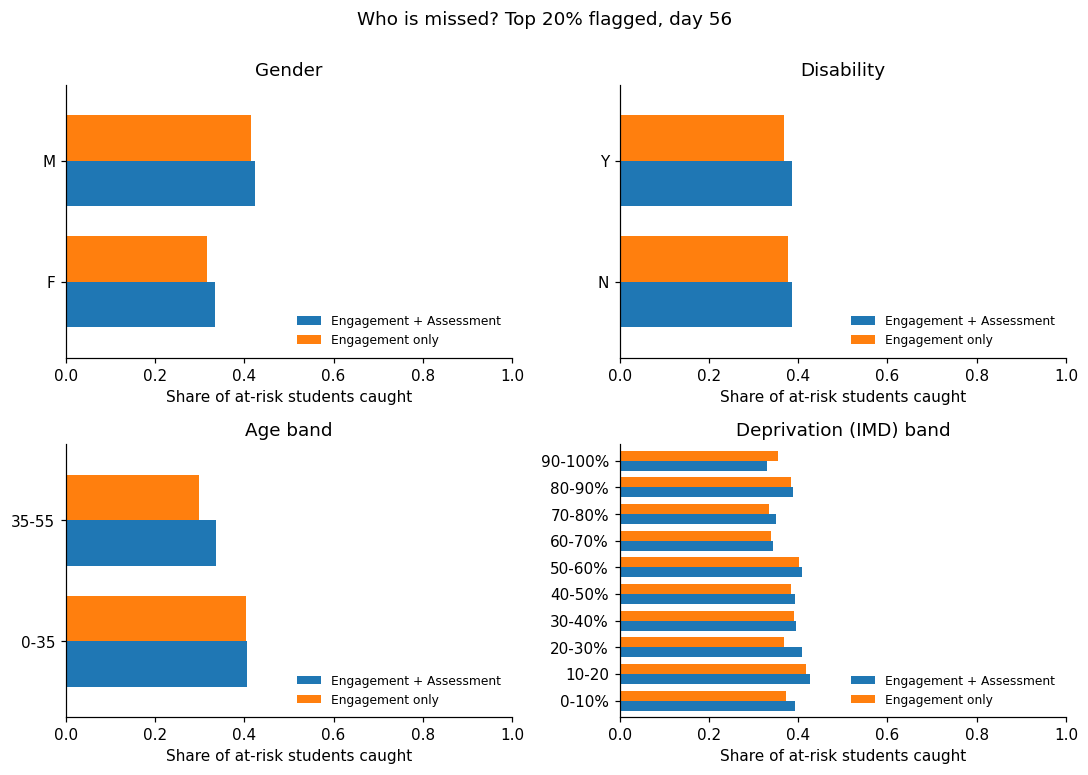

,attribute,group,model,n,n_at_risk,recall_at_top20
0,Gender,F,Engagement only,6456,2539,0.317
1,Gender,F,Engagement + Assessment,6456,2539,0.334
2,Gender,M,Engagement only,8631,3734,0.416
3,Gender,M,Engagement + Assessment,8631,3734,0.423
4,Disability,N,Engagement only,13677,5548,0.377
5,Disability,N,Engagement + Assessment,13677,5548,0.387
6,Disability,Y,Engagement only,1410,725,0.368
7,Disability,Y,Engagement + Assessment,1410,725,0.386
8,Age band,0-35,Engagement only,10487,4562,0.405
9,Age band,0-35,Engagement + Assessment,10487,4562,0.407


In [11]:
FLAG = 0.20
attrs = {"gender": "Gender", "disability": "Disability", "age_band": "Age band", "imd_band": "Deprivation (IMD) band"}
te_main = primary_df[primary_df["split"] == "test"].reset_index(drop=True)
y = te_main["at_risk"].values
flag = {}
for fs_name in ["Engagement only", "Engagement + Assessment"]:
    s = primary_scores[fs_name]
    thr = np.quantile(s, 1 - FLAG)
    flag[fs_name] = (s >= thr).astype(int)
audit = []
for a, label in attrs.items():
    for grp, sub in te_main.groupby(a):
        idx = sub.index.values
        pos = y[idx].sum()
        if len(idx) < 150 or pos < 30:
            continue
        for fs_name in flag:
            rec_g = flag[fs_name][idx][y[idx] == 1].mean()
            audit.append(dict(attribute=label, group=str(grp), model=fs_name, n=len(idx),
                              n_at_risk=int(pos), recall_at_top20=float(rec_g)))
audit = pd.DataFrame(audit)
audit.round(3).to_csv(f"{OUT}/table_group_audit.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (a, label) in zip(axes.ravel(), attrs.items()):
    sub = audit[audit["attribute"] == label]
    if sub.empty:
        ax.set_visible(False); continue
    piv = sub.pivot(index="group", columns="model", values="recall_at_top20")
    piv.plot(kind="barh", ax=ax, width=0.75)
    ax.set_title(label); ax.set_xlabel("Share of at-risk students caught"); ax.set_ylabel("")
    ax.set_xlim(0, 1); ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle(f"Who is missed? Top {int(FLAG*100)}% flagged, day {PRIMARY}", y=1.0)
fig.tight_layout(); fig.savefig(f"{OUT}/fig4_group_audit.png"); plt.show()
audit.round(3)

In [12]:
g56 = results[(results.cutoff_day == PRIMARY) & (results.model == "gb")].set_index("features")
lines = []
lines.append(f"Enrollments total: {len(student_info)} | unique students: {student_info['id_student'].nunique()}")
lines.append(f"Main cutoff: day {PRIMARY}; test n = {len(te_main)}; at-risk rate (test) = {y.mean():.3f}")
for fs_name in FEATURE_SETS:
    r = g56.loc[fs_name]
    lines.append(f"[GB] {fs_name}: AUC={r['auc']:.3f}, AP={r['ap']:.3f}, precision@10%={r['precision_at_10pct']:.3f}")
g56l = results[(results.cutoff_day == PRIMARY) & (results.model == "lr")].set_index("features")
for fs_name in FEATURE_SETS:
    lines.append(f"[LR] {fs_name}: AUC={g56l.loc[fs_name, 'auc']:.3f}")
lines.append(f"Share of at-risk students with HIGH engagement (above module median): {high_eng_share_of_atrisk:.3f}")
lines.append("Fail-rate by engagement level (row %):\n" + ct_pct.round(1).to_string())
lines.append("Group audit (recall at top 20%):\n" + audit.round(3).to_string(index=False))
summary = "\n".join(lines)
open(f"{OUT}/summary.txt", "w").write(summary)
print(summary)

Enrollments total: 32593 | unique students: 28785
Main cutoff: day 56; test n = 15087; at-risk rate (test) = 0.416
[GB] Engagement only: AUC=0.750, AP=0.708, precision@10%=0.894
[GB] Assessment only: AUC=0.767, AP=0.703, precision@10%=0.899
[GB] Engagement + Assessment: AUC=0.793, AP=0.750, precision@10%=0.910
[LR] Engagement only: AUC=0.749
[LR] Assessment only: AUC=0.760
[LR] Engagement + Assessment: AUC=0.798
Share of at-risk students with HIGH engagement (above module median): 0.320
Fail-rate by engagement level (row %):
Outcome              Fail / Withdrawn  Pass / Distinction
Engagement                                               
High (above median)              26.8                73.2
Low (below median)               57.2                42.8
Group audit (recall at top 20%):
             attribute   group                   model     n  n_at_risk  recall_at_top20
                Gender       F         Engagement only  6456       2539            0.317
                Gender    

In [13]:
import shutil
shutil.make_archive("outputs", "zip", OUT)
try:
    from google.colab import files
    files.download("outputs.zip")
except Exception:
    print("Saved: outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
rng = np.random.default_rng(SEED)
y_arr = te_main["at_risk"].values
names = ["Engagement only", "Assessment only", "Engagement + Assessment"]
S = {k: primary_scores[k] for k in names}
B = 1000
n = len(y_arr)
boot = {k: [] for k in names}
d_ae, d_be = [], []
for _ in range(B):
    idx = rng.integers(0, n, n)
    yb = y_arr[idx]
    a = {k: roc_auc_score(yb, S[k][idx]) for k in names}
    for k in names:
        boot[k].append(a[k])
    d_ae.append(a["Assessment only"] - a["Engagement only"])
    d_be.append(a["Engagement + Assessment"] - a["Engagement only"])

def ci(v):
    return np.percentile(v, [2.5, 97.5])

lines_b = []
for k in names:
    lo, hi = ci(boot[k])
    lines_b.append(f"AUC {k}: {roc_auc_score(y_arr, S[k]):.3f} (95% CI {lo:.3f}-{hi:.3f})")
for label, v in [("Assessment - Engagement", d_ae), ("Both - Engagement", d_be)]:
    lo, hi = ci(v)
    lines_b.append(f"AUC difference {label}: {np.mean(v):.3f} (95% CI {lo:.3f} to {hi:.3f})")
boot_summary = "\n".join(lines_b)
open(f"{OUT}/bootstrap_summary.txt", "w").write(boot_summary)
print(boot_summary)

AUC Engagement only: 0.750 (95% CI 0.741-0.758)
AUC Assessment only: 0.767 (95% CI 0.758-0.774)
AUC Engagement + Assessment: 0.793 (95% CI 0.786-0.800)
AUC difference Assessment - Engagement: 0.017 (95% CI 0.008 to 0.026)
AUC difference Both - Engagement: 0.044 (95% CI 0.037 to 0.050)


Gender gap (M minus F), Engagement only: 0.100 (95% CI 0.077 to 0.125)
Age band gap (35-55 minus 0-35), Engagement only: -0.107 (95% CI -0.134 to -0.081)
Gender gap (M minus F), Engagement + Assessment: 0.090 (95% CI 0.066 to 0.114)
Age band gap (35-55 minus 0-35), Engagement + Assessment: -0.071 (95% CI -0.097 to -0.043)


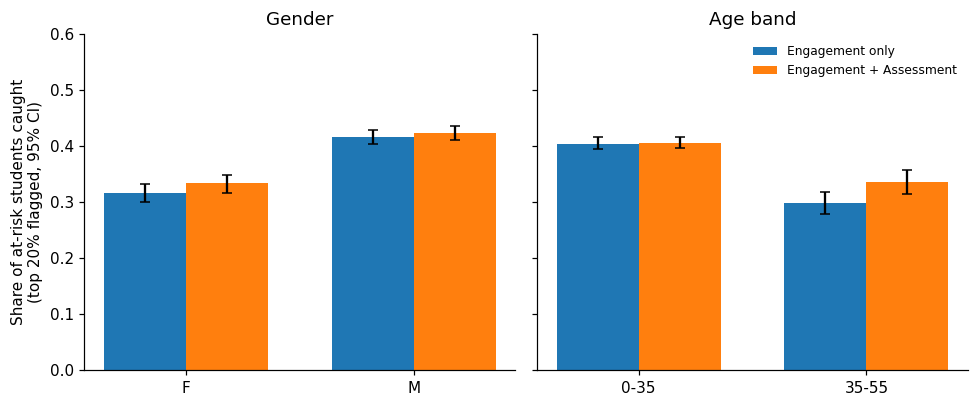

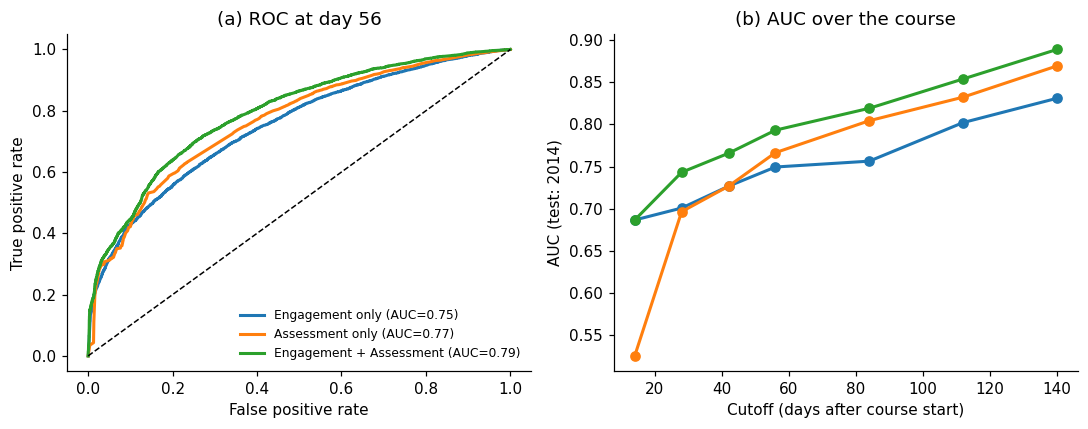

In [15]:
rng = np.random.default_rng(SEED)
y_arr = te_main["at_risk"].values
n = len(y_arr)
M_ENG, M_BOTH = "Engagement only", "Engagement + Assessment"
sc = {M_ENG: primary_scores[M_ENG], M_BOTH: primary_scores[M_BOTH]}
groups = {"Gender": ("gender", ["F", "M"]), "Age band": ("age_band", ["0-35", "35-55"])}
gvals = {k: te_main[col].astype(str).values for k, (col, _) in groups.items()}

def recalls(idx):
    out = {}
    yb = y_arr[idx]
    for m, s in sc.items():
        sb = s[idx]
        flag = sb >= np.quantile(sb, 1 - FLAG)
        for gname, (_, levels) in groups.items():
            gb = gvals[gname][idx]
            for lv in levels:
                mask = (gb == lv) & (yb == 1)
                out[(m, gname, lv)] = flag[mask].mean() if mask.sum() else np.nan
    return out

point = recalls(np.arange(n))
boots = {k: [] for k in point}
gaps = {(m, g): [] for m in sc for g in groups}
for _ in range(1000):
    idx = rng.integers(0, n, n)
    r = recalls(idx)
    for k, v in r.items():
        boots[k].append(v)
    for m in sc:
        for g, (_, lv) in groups.items():
            gaps[(m, g)].append(r[(m, g, lv[1])] - r[(m, g, lv[0])])

txt = []
for (m, g), v in gaps.items():
    lo, hi = np.nanpercentile(v, [2.5, 97.5])
    lv = groups[g][1]
    txt.append(f"{g} gap ({lv[1]} minus {lv[0]}), {m}: {np.nanmean(v):.3f} (95% CI {lo:.3f} to {hi:.3f})")
gap_text = "\n".join(txt)
open(f"{OUT}/bootstrap_groups.txt", "w").write(gap_text)
print(gap_text)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
width = 0.36
for ax, (gname, (_, levels)) in zip(axes, groups.items()):
    xs = np.arange(len(levels))
    for j, m in enumerate([M_ENG, M_BOTH]):
        vals = [point[(m, gname, lv)] for lv in levels]
        err = [[point[(m, gname, lv)] - np.nanpercentile(boots[(m, gname, lv)], 2.5) for lv in levels],
               [np.nanpercentile(boots[(m, gname, lv)], 97.5) - point[(m, gname, lv)] for lv in levels]]
        ax.bar(xs + (j - 0.5) * width, vals, width, yerr=err, capsize=3, label=m)
    ax.set_xticks(xs); ax.set_xticklabels(levels)
    ax.set_title(gname); ax.set_ylim(0, 0.6)
axes[0].set_ylabel("Share of at-risk students caught\n(top 20% flagged, 95% CI)")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout(); fig.savefig(f"{OUT}/fig4_simple.png"); plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.0))
for fs_name, s in primary_scores.items():
    fpr, tpr, _ = roc_curve(y_arr, s)
    a1.plot(fpr, tpr, lw=2, label=f"{fs_name} (AUC={roc_auc_score(y_arr, s):.2f})")
a1.plot([0, 1], [0, 1], "k--", lw=1)
a1.set_xlabel("False positive rate"); a1.set_ylabel("True positive rate")
a1.set_title(f"(a) ROC at day {PRIMARY}"); a1.legend(frameon=False, fontsize=8, loc="lower right")
gbr = results[results["model"] == "gb"]
for fs_name in FEATURE_SETS:
    g = gbr[gbr["features"] == fs_name].sort_values("cutoff_day")
    a2.plot(g["cutoff_day"], g["auc"], marker="o", lw=2, label=fs_name)
a2.set_xlabel("Cutoff (days after course start)"); a2.set_ylabel("AUC (test: 2014)")
a2.set_title("(b) AUC over the course")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_main_roc_and_time.png"); plt.show()

In [16]:
def add_rank_feats(df):
    g = df.groupby(["code_module", "code_presentation"])
    for c in ENG:
        df[c + "_rk"] = g[c].rank(pct=True)
    return df

ENG_RK = [c + "_rk" for c in ENG]
SETS_R = {"Engagement (raw)": ENG,
          "Engagement (rank within course)": ENG_RK,
          "Assessment only": LEARN,
          "Both (raw)": ENG + LEARN,
          "Both (rank within course)": ENG_RK + LEARN}
rob_rows = []
for T in [PRIMARY, 84, 112]:
    df = add_rank_feats(build_features(T))
    tr = df[df["split"] == "train"]
    te_all = df[df["split"] == "test"]
    for test_name, te in [("all test", te_all),
                          ("test without CCC", te_all[te_all["code_module"] != "CCC"])]:
        for fs_name, cols in SETS_R.items():
            pipe = make_pipe("gb", cols)
            pipe.fit(tr[cols + CAT], tr["at_risk"].values)
            s = pipe.predict_proba(te[cols + CAT])[:, 1]
            yte = te["at_risk"].values
            rob_rows.append(dict(cutoff_day=T, test_set=test_name, features=fs_name, n_test=len(te),
                                 auc=roc_auc_score(yte, s), ap=average_precision_score(yte, s),
                                 precision_at_10pct=precision_at_k(yte, s, 0.10)))
rob = pd.DataFrame(rob_rows).round(3)
rob.to_csv(f"{OUT}/table_robustness.csv", index=False)
print(rob.to_string(index=False))

 cutoff_day         test_set                        features  n_test   auc    ap  precision_at_10pct
         56         all test                Engagement (raw)   15087 0.750 0.708               0.894
         56         all test Engagement (rank within course)   15087 0.751 0.711               0.891
         56         all test                 Assessment only   15087 0.767 0.703               0.899
         56         all test                      Both (raw)   15087 0.793 0.750               0.910
         56         all test       Both (rank within course)   15087 0.794 0.753               0.910
         56 test without CCC                Engagement (raw)   11848 0.751 0.698               0.888
         56 test without CCC Engagement (rank within course)   11848 0.755 0.703               0.888
         56 test without CCC                 Assessment only   11848 0.757 0.670               0.875
         56 test without CCC                      Both (raw)   11848 0.786 0.725           

In [17]:
d3 = primary_df.copy()
d3["eng_rank"] = d3.groupby(["code_module", "code_presentation"])["total_clicks"].rank(pct=True)
d3_te = d3[d3["split"] == "test"].reset_index(drop=True)
te_chk = primary_df[primary_df["split"] == "test"].reset_index(drop=True)
assert d3_te[KEY].equals(te_chk[KEY])
y_t = te_chk["at_risk"].values
high = (d3_te["eng_rank"] > 0.5).values
FLAGF = 0.20
fr = te_chk["final_result"].values
lines = [f"Base rate at-risk (test): {y_t.mean():.3f}; max possible sensitivity with {int(FLAGF*100)}% flagged: {FLAGF / y_t.mean():.3f}"]
for name in ["Engagement only", "Engagement + Assessment"]:
    s = primary_scores[name]
    flag = s >= np.quantile(s, 1 - FLAGF)
    m_hi = high & (y_t == 1)
    m_lo = (~high) & (y_t == 1)
    lines.append(f"[{name}] overall sensitivity {flag[y_t == 1].mean():.3f}")
    lines.append(f"  at-risk with HIGH engagement: n={m_hi.sum()}, sensitivity {flag[m_hi].mean():.3f}")
    lines.append(f"  at-risk with LOW engagement:  n={m_lo.sum()}, sensitivity {flag[m_lo].mean():.3f}")
    for lab in ["Fail", "Withdrawn"]:
        m = fr == lab
        lines.append(f"  {lab}: n={m.sum()}, sensitivity {flag[m].mean():.3f}")
    for col, levels in [("gender", ["F", "M"]), ("age_band", ["0-35", "35-55"])]:
        for lv in levels:
            for lab in ["Fail", "Withdrawn"]:
                m = (te_chk[col].astype(str).values == lv) & (fr == lab)
                if m.sum() > 0:
                    lines.append(f"  {col}={lv}, {lab}: n={m.sum()}, sensitivity {flag[m].mean():.3f}")
check_text = "\n".join(lines)
open(f"{OUT}/model_check.txt", "w").write(check_text)
print(check_text)

Base rate at-risk (test): 0.416; max possible sensitivity with 20% flagged: 0.481
[Engagement only] overall sensitivity 0.376
  at-risk with HIGH engagement: n=2005, sensitivity 0.071
  at-risk with LOW engagement:  n=4268, sensitivity 0.519
  Fail: n=3806, sensitivity 0.401
  Withdrawn: n=2467, sensitivity 0.336
  gender=F, Fail: n=1569, sensitivity 0.329
  gender=F, Withdrawn: n=970, sensitivity 0.298
  gender=M, Fail: n=2237, sensitivity 0.452
  gender=M, Withdrawn: n=1497, sensitivity 0.361
  age_band=0-35, Fail: n=2822, sensitivity 0.430
  age_band=0-35, Withdrawn: n=1740, sensitivity 0.364
  age_band=35-55, Fail: n=963, sensitivity 0.318
  age_band=35-55, Withdrawn: n=712, sensitivity 0.272
[Engagement + Assessment] overall sensitivity 0.387
  at-risk with HIGH engagement: n=2005, sensitivity 0.183
  at-risk with LOW engagement:  n=4268, sensitivity 0.483
  Fail: n=3806, sensitivity 0.383
  Withdrawn: n=2467, sensitivity 0.393
  gender=F, Fail: n=1569, sensitivity 0.319
  gender=